# Semantic scheduler: downloaded run review

This notebook reads one completed Kaggle output directory. It does **not** retrain or require images, a GPU, or repository imports. Run it top to bottom after downloading the kernel outputs. Tables and charts are computed from the files found in the selected run.

**Reading rule:** DQN validation scores are for checkpoint selection; classifier accuracy is for image priority prediction; scheduler utility requires `evaluation/all_policy_metrics.csv`. These are different quantities.

## 1. Locate the run and check what was downloaded

Set `RUN_ROOT_OVERRIDE` if your files are outside the repository. The default selects the most complete matching run under `downloaded/`, preferring `train-final-cli`. A partial Kaggle download is common after cancelling a version, so the inventory is a required first step.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_ROOT_OVERRIDE = None  # Example: Path(r"D:\downloads\outputs\20260929T021341Z-d3338ef4")

def find_project_root(start):
    for parent in (start, *start.parents):
        if (parent / "PROJECT_MAP.md").is_file():
            return parent
    raise FileNotFoundError("Open this notebook from the repository, or set RUN_ROOT_OVERRIDE")

project_root = find_project_root(Path.cwd().resolve())
if RUN_ROOT_OVERRIDE is not None:
    run_root = Path(RUN_ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = list((project_root / "downloaded").glob("*/outputs/*/run_manifest.json"))
    if not candidates:
        raise FileNotFoundError("No downloaded run_manifest.json found; set RUN_ROOT_OVERRIDE")
    candidates.sort(key=lambda p: ("train-final-cli" in p.parts, len(list(p.parent.rglob("*")))), reverse=True)
    run_root = candidates[0].parent

if not (run_root / "run_manifest.json").is_file():
    raise FileNotFoundError(f"Run manifest missing under {run_root}")
run_manifest = json.loads((run_root / "run_manifest.json").read_text(encoding="utf-8"))
local_evaluation_root = project_root / "results/scheduler-policy-local/test30_core"
local_provenance_path = local_evaluation_root / "evaluation_provenance.json"
if local_provenance_path.is_file():
    local_provenance = json.loads(local_provenance_path.read_text(encoding="utf-8"))
    if local_provenance.get("training_run_id") != run_manifest.get("run_id"):
        raise ValueError("Local evaluation was created from a different training run")
downloaded_policy_path = run_root / "evaluation/all_policy_metrics.csv"
local_policy_path = local_evaluation_root / "all_policy_metrics.csv"
all_policy_path = downloaded_policy_path if downloaded_policy_path.is_file() else local_policy_path
all_files = sorted(p for p in run_root.rglob("*") if p.is_file())
inventory = pd.DataFrame([{"artifact": p.relative_to(run_root).as_posix(),
                           "bytes": p.stat().st_size} for p in all_files])
print("Run:", run_root)
print("Files:", len(inventory), "| Total MiB:", round(inventory.bytes.sum() / 2**20, 2))
display(inventory.assign(group=inventory.artifact.str.split("/").str[0])
        .groupby("group").agg(files=("artifact", "size"), bytes=("bytes", "sum")))
display(inventory[inventory.artifact.str.startswith("evaluation/")])

Run: D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\downloaded\train-final-cli\outputs\20260929T021341Z-d3338ef4
Files: 45 | Total MiB: 77.12


,files,bytes
group,,
cache,2,3535982
dataset_manifest.csv,1,184606
environment.json,1,321
evaluation,3,54564
feature_cache.jsonl,1,3390688
ladi260_contact_sheet.png,1,20611375
ladi_predictions.json,1,145294
models,27,4962248
payload,1,15138


,artifact,bytes
4,evaluation/priority_classifier_confusion.png,34549
5,evaluation/priority_classifier_metrics.csv,513
6,evaluation/priority_classifier_predictions.csv,19502


In [2]:
required = {
    "training_metrics.csv": "DQN training curves",
    "models/dqn_seed42_manifest.json": "DQN seed metadata",
    "evaluation/priority_classifier_metrics.csv": "priority classification",
    "evaluation/all_policy_metrics.csv": "all-policy scheduler comparison",
    "evaluation/dynamic_paired_priority_gains.csv": "paired gains versus FIFO/EDF",
    "evaluation/evaluation_manifest.json": "finished evaluation provenance",
}
coverage = pd.DataFrame([{"artifact": name, "meaning": meaning,
                          "in_kaggle_download": (run_root / name).is_file(),
                          "in_local_evaluation": (local_evaluation_root / Path(name).name).is_file()}
                         for name, meaning in required.items()])
display(coverage)
expected_hashes = run_manifest.get("artifacts_sha256", {})
hash_rows = []
for relative_name, expected in expected_hashes.items():
    path = run_root / relative_name
    actual = hashlib.sha256(path.read_bytes()).hexdigest() if path.is_file() else None
    hash_rows.append({"artifact": relative_name, "present": path.is_file(), "sha256_matches": actual == expected})
hash_check = pd.DataFrame(hash_rows)
display(hash_check)
if not hash_check.sha256_matches.all():
    display(Markdown("**Integrity warning:** one or more training artifacts are missing or differ from the run manifest."))
if not downloaded_policy_path.is_file():
    if all_policy_path.is_file():
        display(Markdown("**Local evaluation available:** the Kaggle download stopped before all-policy testing, so the policy comparison below comes from a separate local replay of the saved models and cached features."))
    else:
        display(Markdown("**Evaluation incomplete:** no all-policy scheduler results are available yet."))

,artifact,meaning,in_kaggle_download,in_local_evaluation
0,training_metrics.csv,DQN training curves,True,False
1,models/dqn_seed42_manifest.json,DQN seed metadata,True,False
2,evaluation/priority_classifier_metrics.csv,priority classification,True,False
3,evaluation/all_policy_metrics.csv,all-policy scheduler comparison,False,True
4,evaluation/dynamic_paired_priority_gains.csv,paired gains versus FIFO/EDF,False,True
5,evaluation/evaluation_manifest.json,finished evaluation provenance,False,False


,artifact,present,sha256_matches
0,dataset_manifest.csv,True,True
1,feature_cache.jsonl,True,True
2,ladi_predictions.json,True,True
3,models/clip_priority_classifier.npz,True,True
4,models/clip_priority_manifest.json,True,True
5,models/clip_priority_predictions.json,True,True
6,models/dqn_seed42_best.npz,True,True
7,models/dqn_seed43_best.npz,True,True
8,models/dqn_seed44_best.npz,True,True
9,models/ordinal_classifier.npz,True,True


**Local evaluation available:** the Kaggle download stopped before all-policy testing, so the policy comparison below comes from a separate local replay of the saved models and cached features.

## 2. What experiment was run?

The fixed rubric supplies P5/P6/P7 and priority classes; it is a prototype task assumption. P1/P4 use a LADI classifier, P2 uses CLIP task similarity, and P3 is calculated from successfully delivered history during simulation. The download uses **simulated fixed payload units**, so it cannot support claims about actual SwinJSCC channel use or reconstruction quality.

In [3]:
manifest = pd.read_csv(run_root / "dataset_manifest.csv")
payload = pd.read_csv(run_root / "payload_costs.csv")
assert manifest.image_id.is_unique, "The manifest contains duplicate image IDs"
assert set(manifest.image_id) == set(payload.image_id), "Payload rows do not match images"
summary = {
    "run_id": run_manifest.get("run_id"),
    "git_commit": run_manifest.get("git_commit"),
    "images": len(manifest),
    "selection_strata": manifest.selection_stratum.nunique(),
    "evidence_groups": manifest.evidence_group_id.nunique(),
    "payload_mode": run_manifest.get("payload_mode"),
    "resource_unit": run_manifest.get("resource_unit"),
    "dataset_annotation_source": ", ".join(sorted(manifest.annotation_source.dropna().unique())),
}
display(pd.DataFrame(summary.items(), columns=["item", "value"]))
display(pd.crosstab(manifest.selection_stratum, manifest.split))
display(pd.crosstab(manifest.base_priority, manifest.split).rename_axis("priority (0 = highest)"))
group_split_counts = manifest.groupby("evidence_group_id").split.nunique()
print("Evidence groups crossing splits:", int((group_split_counts > 1).sum()))
print("Simulated payload units per image:", sorted(payload.resource_units.unique().tolist()))

,item,value
0,run_id,20260929T021341Z-d3338ef4
1,git_commit,d3338ef4faf553d83c2f0b868eb150aa9ab4a936
2,images,260
3,selection_strata,12
4,evidence_groups,130
5,payload_mode,simulated_fixed
6,resource_unit,simulated_units
7,dataset_annotation_source,prototype_default_no_human_review


split,test,train,validation
selection_stratum,,,
bridges_any,4,14,4
buildings_affected_or_greater,4,14,4
buildings_any,4,14,4
buildings_minor_or_greater,4,14,4
debris_any,4,14,4
flooding_any,4,14,4
flooding_structures,4,14,4
roads_any,4,14,4
roads_damage,4,14,4


split,test,train,validation
priority (0 = highest),,,
0,4,14,4
1,16,56,16
2,22,64,22
3,10,22,10


Evidence groups crossing splits: 0
Simulated payload units per image: [10]


## 3. Extracted semantic parameters and timing

This chart summarizes static per-image features. **P3 is expected to be unavailable in this cache**: it changes at each scheduling decision as the receiver history changes. P5/P6/P7 come from the fixed rubric, so their apparent predictive strength should not be interpreted as a fully automatic image understanding result.

,parameter,available_images
0,scene_importance,260
1,context_relevance,260
2,delivered_history_novelty,0
3,interpretation_confidence,260
4,task_impact,260
5,urgency,260
6,evidence_sufficiency,260


,extraction_latency_ms,process_cpu_ms,gpu_peak_allocated_bytes
count,260.00,260.00,260.0
mean,268.76,227.91,767176192.0
std,2424.08,1767.10,0.0
min,78.93,78.82,767176192.0
50%,119.82,119.78,767176192.0
95%,133.79,133.90,767176192.0
max,39205.19,28611.49,767176192.0


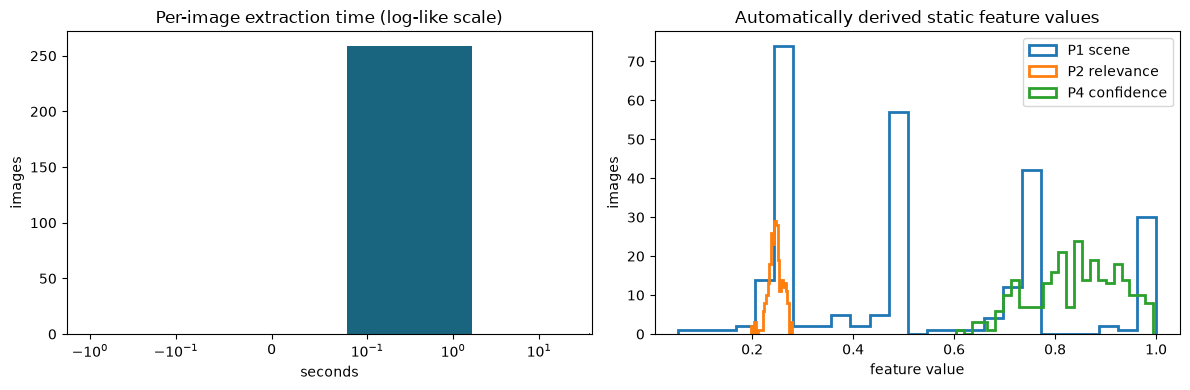

In [4]:
feature_rows = [json.loads(line) for line in (run_root / "feature_cache.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()]
parameter_names = ["scene_importance", "context_relevance", "delivered_history_novelty",
                   "interpretation_confidence", "task_impact", "urgency", "evidence_sufficiency"]
flat_rows = []
for row in feature_rows:
    output = {"image_id": row["image_id"], "extraction_latency_ms": row.get("extraction_latency_ms"),
              "process_cpu_ms": row.get("process_cpu_ms"), "gpu_peak_allocated_bytes": row.get("gpu_peak_allocated_bytes")}
    for name in parameter_names:
        item = row["features"].get(name, {})
        output[name] = item.get("value") if item.get("available") else np.nan
        output[name + "_available"] = bool(item.get("available", False))
    flat_rows.append(output)
features = pd.DataFrame(flat_rows).merge(manifest[["image_id", "split", "selection_stratum", "base_priority"]], on="image_id", validate="one_to_one")
assert len(features) == len(manifest)
availability = pd.DataFrame({"parameter": parameter_names,
                             "available_images": [int(features[name + "_available"].sum()) for name in parameter_names]})
display(availability)
display(features[["extraction_latency_ms", "process_cpu_ms", "gpu_peak_allocated_bytes"]].describe(percentiles=[.5, .95]).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
latency_seconds = features.extraction_latency_ms / 1000
latency_seconds.plot.hist(bins=25, ax=axes[0], color="#19647e")
axes[0].set_xscale("symlog", linthresh=.1)
axes[0].set(title="Per-image extraction time (log-like scale)", xlabel="seconds", ylabel="images")
for name, label in [("scene_importance", "P1 scene"), ("context_relevance", "P2 relevance"),
                    ("interpretation_confidence", "P4 confidence")]:
    features[name].plot.hist(bins=25, ax=axes[1], histtype="step", linewidth=2, label=label)
axes[1].set(title="Automatically derived static feature values", xlabel="feature value", ylabel="images")
axes[1].legend(); fig.tight_layout(); plt.show()

## 4. Priority classifier quality

Three classifiers predict a rubric-defined priority level (0 is highest). `macro_f1` gives each class equal weight; `balanced_accuracy` averages recall across classes. The feature ordinal model observes rubric-assisted impact and urgency, so compare the two image-only models separately when discussing automatic image interpretation.

,split,model,n_images,macro_f1,balanced_accuracy
2,test,feature_ordinal_oracle_assisted,52,0.857,0.880
1,test,LADI_image_classifier,52,0.581,0.685
0,test,CLIP_image_priority_classifier,52,0.540,0.536
5,validation,feature_ordinal_oracle_assisted,52,0.857,0.880
4,validation,LADI_image_classifier,52,0.492,0.624
3,validation,CLIP_image_priority_classifier,52,0.462,0.474


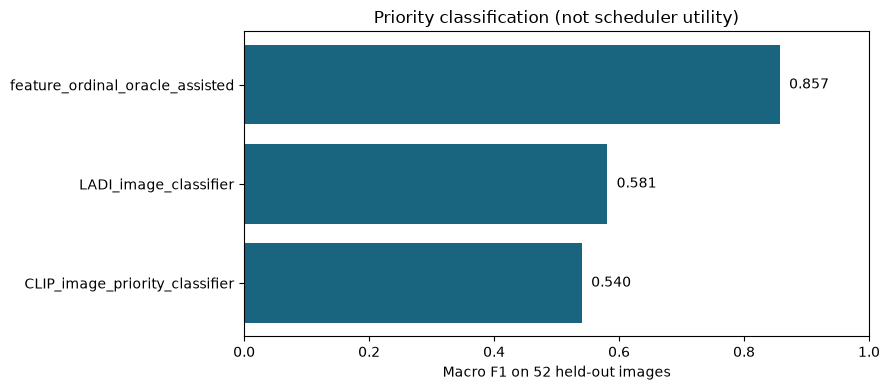

**LADI_image_classifier: test confusion table**

predicted priority,0,1,2,3
true priority,,,,
0,4,0,0,0
1,2,6,4,4
2,0,6,8,8
3,0,0,0,10


**CLIP_image_priority_classifier: test confusion table**

predicted priority,0,1,2,3
true priority,,,,
0,2,1,1,0
1,2,8,5,1
2,0,8,12,2
3,0,3,1,6


**feature_ordinal_oracle_assisted: test confusion table**

predicted priority,0,1,2,3
true priority,,,,
0,4,0,0,0
1,0,15,1,0
2,0,2,15,5
3,0,0,1,9


In [5]:
classifier_metrics = pd.read_csv(run_root / "evaluation/priority_classifier_metrics.csv")
predictions = pd.read_csv(run_root / "evaluation/priority_classifier_predictions.csv")
display(classifier_metrics.sort_values(["split", "macro_f1"], ascending=[True, False]).round(3))
test_scores = classifier_metrics[classifier_metrics.split == "test"].sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(test_scores.model, test_scores.macro_f1, color="#19647e")
ax.set(xlim=(0, 1), xlabel="Macro F1 on 52 held-out images", title="Priority classification (not scheduler utility)")
for y, value in enumerate(test_scores.macro_f1):
    ax.text(value + .015, y, f"{value:.3f}", va="center")
fig.tight_layout(); plt.show()
for model in predictions.model.unique():
    subset = predictions[(predictions.split == "test") & (predictions.model == model)]
    table = pd.crosstab(subset.true_priority, subset.predicted_priority,
                        rownames=["true priority"], colnames=["predicted priority"])
    display(Markdown(f"**{model}: test confusion table**"))
    display(table)

## 5. DQN training across three seeds

Each seed starts from a different random state. The best checkpoint is selected by validation semantic-utility AUC. A validation score is **not** an all-policy test comparison. The run used a wall-time cap: each seed can stop before all 300 configured episodes.

,seed,completed_episodes,configured_episodes,minutes,best_validation_utility_auc,stopped_by_time_budget,data_parallel
0,42,168,300,43.374,0.110,True,True
1,43,161,300,43.488,0.115,True,True
2,44,152,300,43.364,0.112,True,True


Selected by validation: 43
Invalid actions during training: 0
Loss trend is a diagnostic, not proof of convergence; use held-out policy evaluation for the scheduling claim.


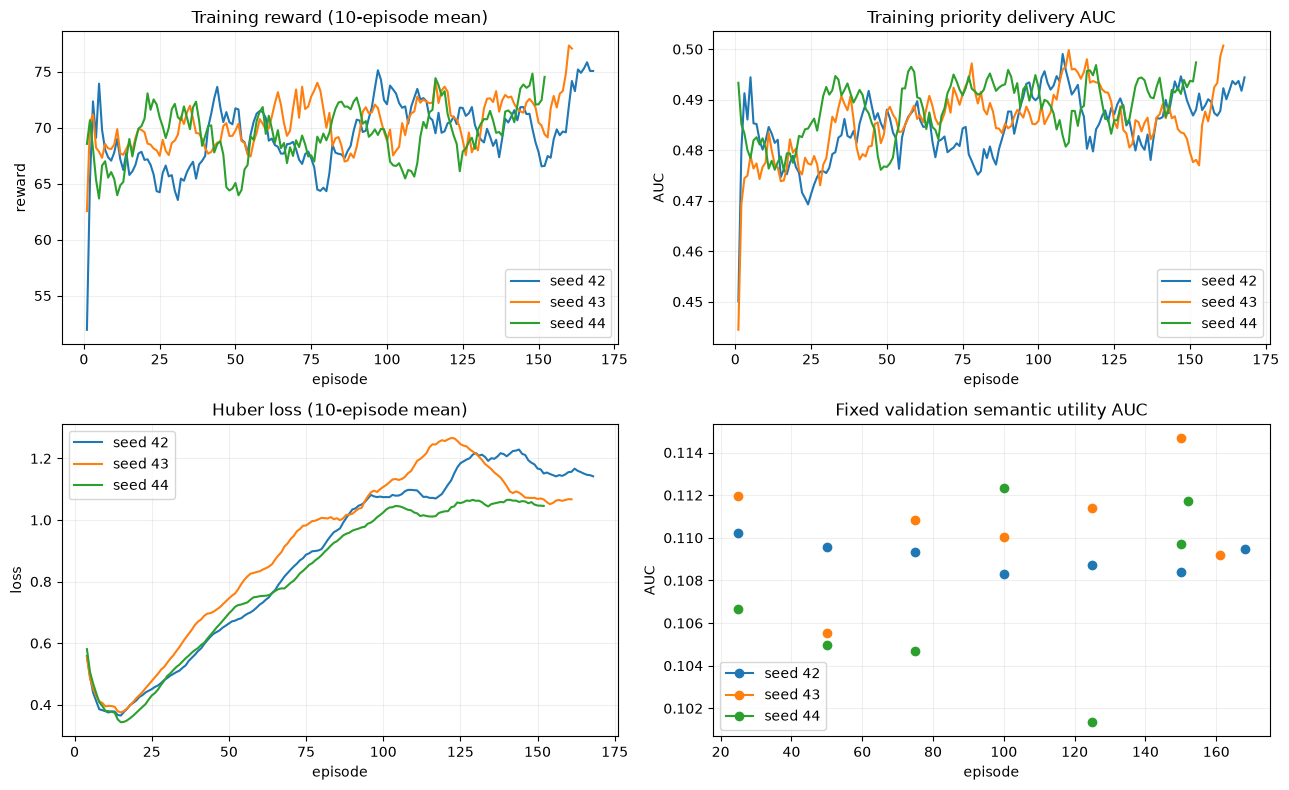

In [6]:
training = pd.read_csv(run_root / "training_metrics.csv")
seed_rows = []
for path in sorted((run_root / "models").glob("dqn_seed*_manifest.json")):
    record = json.loads(path.read_text(encoding="utf-8"))
    seed_rows.append({"seed": record["seed"], "completed_episodes": record["completed_episodes"],
                      "configured_episodes": record["configured_episodes"],
                      "minutes": record["elapsed_seconds"] / 60,
                      "best_validation_utility_auc": record["best_validation_semantic_utility_auc"],
                      "stopped_by_time_budget": record["stopped_by_time_budget"],
                      "data_parallel": record["provenance"].get("dqn_data_parallel")})
seeds = pd.DataFrame(seed_rows).sort_values("seed")
display(seeds.round(3))
best_seed = int(seeds.loc[seeds.best_validation_utility_auc.idxmax(), "seed"])
print("Selected by validation:", best_seed)
print("Invalid actions during training:", int(training.invalid_action_count.sum()))
print("Loss trend is a diagnostic, not proof of convergence; use held-out policy evaluation for the scheduling claim.")
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for seed, group in training.groupby("seed"):
    group = group.sort_values("episode")
    label = f"seed {seed}"
    axes[0, 0].plot(group.episode, group.reward.rolling(10, min_periods=1).mean(), label=label)
    axes[0, 1].plot(group.episode, group.training_priority_delivery_auc.rolling(10, min_periods=1).mean(), label=label)
    axes[1, 0].plot(group.episode, group.loss.rolling(10, min_periods=1).mean(), label=label)
    axes[1, 1].plot(group.episode, group.validation_semantic_utility_auc, marker="o", label=label)
axes[0, 0].set(title="Training reward (10-episode mean)", xlabel="episode", ylabel="reward")
axes[0, 1].set(title="Training priority delivery AUC", xlabel="episode", ylabel="AUC")
axes[1, 0].set(title="Huber loss (10-episode mean)", xlabel="episode", ylabel="loss")
axes[1, 1].set(title="Fixed validation semantic utility AUC", xlabel="episode", ylabel="AUC")
for ax in axes.flat:
    ax.grid(alpha=.2)
    ax.legend()
fig.tight_layout(); plt.show()

## 6. All-policy scheduler evaluation, if present

This section deliberately waits for the actual scheduler results. It compares policies only when the same evaluation artifact contains their outcomes. Normalized semantic utility AUC rewards useful early delivery; higher is better. Critical on-time rate is also higher-is-better. Weighted priority inversion and inference latency are lower-is-better. The paired-gains file measures differences on identical episodes against FIFO and EDF.

Source: D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\results\scheduler-policy-local\test30_core\all_policy_metrics.csv
Tracks: ['image_disjoint_distinct']
Policies: ['aging', 'clip_image_priority', 'clip_image_priority_edf', 'dqn', 'edf', 'feature_ordinal_classifier', 'fifo', 'fixed_priority', 'ladi_classifier_priority', 'pairwise_linear_ranker', 'priority_edf', 'privileged_marginal_utility', 'semantic_greedy', 'semantic_lexicographic', 'semantic_weighted', 'sjf', 'ue_round_robin']


**Evaluation track:** `image_disjoint_distinct`; means, spread, and number of episodes.

normalized_utility_auc                \
                                              mean     std count   
policy                                                             
aging                                       0.4051  0.0199    30   
clip_image_priority                         0.4566  0.0168    30   
clip_image_priority_edf                     0.4586  0.0151    30   
dqn                                         0.4453  0.0160    30   
edf                                         0.4096  0.0225    30   
feature_ordinal_classifier                  0.4286  0.0191    30   
fifo                                        0.4051  0.0199    30   
fixed_priority                              0.4325  0.0196    30   
ladi_classifier_priority                    0.4335  0.0179    30   
pairwise_linear_ranker                      0.4285  0.0205    30   
priority_edf                                0.4344  0.0156    30   
privileged_marginal_utility                 0.4801  0.0072    30   
semantic_greedy                             0.4314  0.0210    30   
semantic_lexicographic                      0.4281  0.0176    30   
semantic_weighted                           0.4296  0.0197    30   
sjf                                         0.4051  0.0199    30   
ue_round_robin                              0.4125  0.0190    30   

                            critical_on_time_rate                \
                                             mean     std count   
policy                                                            
aging                                      0.7283  0.1088    30   
clip_image_priority                        0.8217  0.0583    30   
clip_image_priority_edf                    0.7900  0.0498    30   
dqn                                        0.7150  0.0930    30   
edf                                        0.6033  0.1181    30   
feature_ordinal_classifier                 0.9900  0.0242    30   
fifo                                       0.7283  0.1088    30   
fixed_priority                             1.0000  0.0000    30   
ladi_classifier_priority                   0.8200  0.0484    30   
pairwise_linear_ranker                     0.9783  0.0313    30   
priority_edf                               1.0000  0.0000    30   
privileged_marginal_utility                0.7683  0.0609    30   
semantic_greedy                            0.9783  0.0364    30   
semantic_lexicographic                     0.9817  0.0307    30   
semantic_weighted                          0.9683  0.0425    30   
sjf                                        0.7283  0.1088    30   
ue_round_robin                             0.7050  0.0913    30   

                            weighted_priority_inversion                 \
                                                   mean      std count   
policy                                                                   
aging                                          180.8333  24.4019    30   
clip_image_priority                             55.9333  15.8613    30   
clip_image_priority_edf                         73.2000  12.9519    30   
dqn                                            110.1667  34.2879    30   
edf                                            202.1333  23.7178    30   
feature_ordinal_classifier                       2.7667   1.6750    30   
fifo                                           180.8333  24.4019    30   
fixed_priority                                   0.0000   0.0000    30   
ladi_classifier_priority                        34.4667   8.8463    30   
pairwise_linear_ranker                           4.3667   2.7353    30   
priority_edf                                     0.0000   0.0000    30   
privileged_marginal_utility                     96.7000  23.0863    30   
semantic_greedy                                  6.6333   3.4986    30   
semantic_lexicographic                           3.6333   2.4138    30   
semantic_weighted                                7.3333   3.8267    

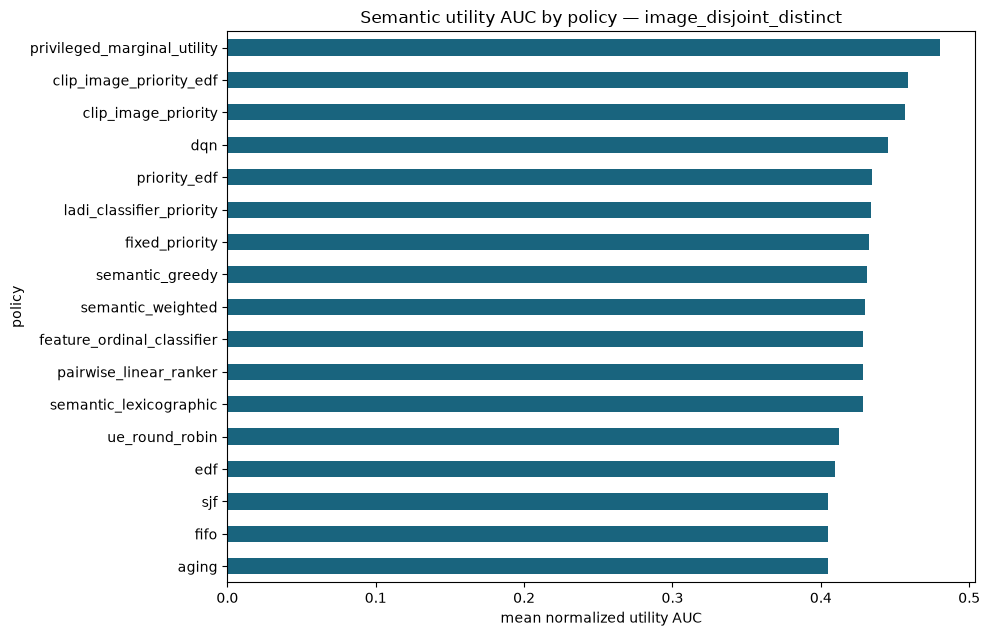

,gain_vs_fifo,gain_vs_edf
policy,,
aging,0.0000,-0.0045
clip_image_priority,0.0514,0.0470
clip_image_priority_edf,0.0534,0.0490
dqn,0.0402,0.0357
edf,0.0045,0.0000
feature_ordinal_classifier,0.0234,0.0190
fifo,0.0000,-0.0045
fixed_priority,0.0273,0.0229
ladi_classifier_priority,0.0284,0.0239


**Paired semantic utility gains.** Intervals resample traffic streams; the same 52 test images recur across streams.

,policy,baseline,paired_gain,ci95_low,ci95_high,streams
23,privileged_marginal_utility,edf,0.0705,0.0624,0.0788,30
5,clip_image_priority_edf,edf,0.0490,0.0417,0.0567,30
3,clip_image_priority,edf,0.0470,0.0388,0.0548,30
7,dqn,edf,0.0357,0.0264,0.0451,30
21,priority_edf,edf,0.0248,0.0170,0.0330,30
17,ladi_classifier_priority,edf,0.0239,0.0157,0.0325,30
15,fixed_priority,edf,0.0229,0.0119,0.0334,30
25,semantic_greedy,edf,0.0218,0.0115,0.0319,30
29,semantic_weighted,edf,0.0200,0.0105,0.0288,30
11,feature_ordinal_classifier,edf,0.0190,0.0101,0.0271,30


In [7]:
policy_path = all_policy_path
if not policy_path.is_file():
    display(Markdown("**Unavailable in this download.** The Kaggle run was cancelled after classifier evaluation. No FIFO, EDF, semantic-greedy, ranker, or DQN test comparison is present; do not infer a winner from DQN validation scores."))
else:
    policy_metrics = pd.read_csv(policy_path)
    print("Source:", policy_path)
    print("Tracks:", policy_metrics.track.unique().tolist())
    print("Policies:", sorted(policy_metrics.policy.unique().tolist()))
    preferred = "image_disjoint_distinct"
    track = preferred if preferred in set(policy_metrics.track) else policy_metrics.track.iloc[0]
    comparison = policy_metrics[policy_metrics.track == track]
    numeric = [name for name in ("normalized_utility_auc", "critical_on_time_rate",
                                 "weighted_priority_inversion", "mean_policy_inference_ms")
               if name in comparison]
    table = comparison.groupby("policy")[numeric].agg(["mean", "std", "count"])
    display(Markdown(f"**Evaluation track:** `{track}`; means, spread, and number of episodes."))
    display(table.round(4))
    if "normalized_utility_auc" in numeric:
        means = comparison.groupby("policy").normalized_utility_auc.mean().sort_values()
        ax = means.plot.barh(figsize=(10, max(4, .38 * len(means))), color="#19647e")
        ax.set(title=f"Semantic utility AUC by policy — {track}", xlabel="mean normalized utility AUC", ylabel="policy")
        plt.tight_layout(); plt.show()
    paired_path = (run_root / "evaluation/dynamic_paired_priority_gains.csv"
                   if downloaded_policy_path.is_file()
                   else local_evaluation_root / "dynamic_paired_priority_gains.csv")
    if paired_path.is_file():
        paired = pd.read_csv(paired_path)
        columns = [name for name in ("gain_vs_fifo", "gain_vs_edf") if name in paired]
        paired_track = paired[paired.track == track] if "track" in paired else paired
        display(paired_track.groupby("policy")[columns].mean().round(4))
    pivot = comparison.pivot_table(index="episode_id", columns="policy",
                                   values="normalized_utility_auc", aggfunc="first")
    if {"fifo", "edf"}.issubset(pivot.columns):
        rng = np.random.default_rng(2026)
        effect_rows = []
        for policy in pivot.columns:
            for baseline in ("fifo", "edf"):
                differences = (pivot[policy] - pivot[baseline]).dropna().to_numpy()
                if len(differences) < 2:
                    continue
                samples = rng.choice(differences, size=(2000, len(differences)), replace=True).mean(axis=1)
                effect_rows.append({"policy": policy, "baseline": baseline,
                                    "paired_gain": differences.mean(),
                                    "ci95_low": np.quantile(samples, .025),
                                    "ci95_high": np.quantile(samples, .975),
                                    "streams": len(differences)})
        display(Markdown("**Paired semantic utility gains.** Intervals resample traffic streams; the same 52 test images recur across streams."))
        display(pd.DataFrame(effect_rows).sort_values(["baseline", "paired_gain"], ascending=[True, False]).round(4))

## 7. What can we say in the presentation?

Run the cell below for a short evidence ledger based on the actual downloaded artifacts. The key limitation is that simulated payload cost and prototype rubric labels constrain the interpretation of every result.

In [8]:
observations = [
    f"The dataset contains {len(manifest)} unique images in {manifest.selection_stratum.nunique()} selection strata, split "
    + "/".join(str(int(v)) for v in manifest.split.value_counts().reindex(["train", "validation", "test"]).fillna(0))
    + " across train/validation/test.",
    f"Three DQN seeds trained for {seeds.minutes.sum():.1f} total minutes; seed {best_seed} had the highest recorded validation utility AUC ({seeds.best_validation_utility_auc.max():.4f}).",
    f"The best test image-only classifier macro F1 is {classifier_metrics[(classifier_metrics.split == 'test') & (classifier_metrics.model != 'feature_ordinal_oracle_assisted')].macro_f1.max():.3f}.",
    "The run used simulated fixed service units and a prototype priority rubric; no measured SwinJSCC reconstruction claim follows from it.",
]
if policy_path.is_file():
    observations.append("All-policy scheduler metrics are present; use the comparison table above for policy claims.")
else:
    observations.append("All-policy scheduler metrics are absent; this download cannot show whether DQN or semantic policies beat FIFO/EDF.")
display(Markdown("\n".join(f"- {sentence}" for sentence in observations)))

- The dataset contains 260 unique images in 12 selection strata, split 156/52/52 across train/validation/test.
- Three DQN seeds trained for 130.2 total minutes; seed 43 had the highest recorded validation utility AUC (0.1147).
- The best test image-only classifier macro F1 is 0.581.
- The run used simulated fixed service units and a prototype priority rubric; no measured SwinJSCC reconstruction claim follows from it.
- All-policy scheduler metrics are present; use the comparison table above for policy claims.